In [14]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd().parent.parent.parent

sys.path.insert(0, str(ROOT))
ROOT

PosixPath('/home/sakana/Code/ManifoldsTeam/woodbench')

# Kiểm chứng `origin_key`: ảnh/view hay mẫu vật gỗ?

Notebook thực hiện mục 3.1–3.7 của hotfix Phase 1B. Toàn bộ đầu ra được lưu riêng tại `artifacts/phase_1b/origin_key_audit/`, không ghi vào `data/experiments`.

Nguồn dữ liệu là manifest 5.572 ảnh đã khử trùng nội dung, trước khi materialize strict split. Đây là nguồn phù hợp để kiểm toán chính heuristic `origin_key`.

> Mục 3.6 là bước thủ công bắt buộc. Notebook chỉ chọn mẫu và tạo form đối chiếu; không suy đoán thông tin sổ mẫu từ filename.


In [15]:
import json
import math
import re
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

MANIFEST_PATH = (
    ROOT
    / 'docs'
    / 'reports'
    / 'phase_1'
    / 'phase_1_leakage_origin_investigation'
    / 'task-B-clean_group_split_plan.csv'
)
ARTIFACT_DIR = ROOT / 'artifacts' / 'phase_1b' / 'origin_key_audit'
HIST_DIR = ARTIFACT_DIR / 'histograms'
HIST_BY_SPECIES_DIR = HIST_DIR / 'by_species'
MANUAL_LOOKUP_PATH = ARTIFACT_DIR / 'sample_book_lookup_20.csv'
RANDOM_SEED = 42
COARSE_ALERT_THRESHOLD = 300
MIN_INDEPENDENT_ORIGINS = 3

EXCLUDED_CLASSES = {
    'Calocedrus sp',
    'Cupressus funebris (Cupressus pendula)',
    'Pinus sp',
}

ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
HIST_BY_SPECIES_DIR.mkdir(parents=True, exist_ok=True)
print(f'Manifest: {MANIFEST_PATH.relative_to(ROOT)}')
print(f'Artifacts: {ARTIFACT_DIR.relative_to(ROOT)}')


Manifest: docs/reports/phase_1/phase_1_leakage_origin_investigation/task-B-clean_group_split_plan.csv
Artifacts: artifacts/phase_1b/origin_key_audit


## 3.1. Danh sách `origin_key` và số ảnh


In [16]:
required_columns = {
    'class_name', 'filename', 'origin_key', 'path', 'old_split', 'new_split'
}
manifest = pd.read_csv(MANIFEST_PATH)
missing_columns = required_columns - set(manifest.columns)
if missing_columns:
    raise ValueError(f'Manifest thiếu cột: {sorted(missing_columns)}')

assert len(manifest) == 5572, 'Manifest không còn đúng mốc 5.572 ảnh'
assert manifest['class_name'].nunique() == 20
assert manifest['origin_key'].nunique() == 557
assert manifest.loc[
    ~manifest['class_name'].isin(EXCLUDED_CLASSES), 'origin_key'
].nunique() == 552

origin_rows = []
for (class_name, origin_key), group in manifest.groupby(
    ['class_name', 'origin_key'], sort=True
):
    origin_rows.append(
        {
            'class_name': class_name,
            'origin_key': origin_key,
            'n_images': len(group),
            'old_splits': ','.join(sorted(group['old_split'].dropna().unique())),
            'new_splits': ','.join(sorted(group['new_split'].dropna().unique())),
            'example_filenames': ' | '.join(group['filename'].astype(str).head(5)),
            'example_paths': ' | '.join(group['path'].astype(str).head(3)),
            'is_final17': class_name not in EXCLUDED_CLASSES,
        }
    )
origins = pd.DataFrame(origin_rows).sort_values(
    ['class_name', 'origin_key']
).reset_index(drop=True)

display(origins.head(20))
print(f'All classes: {len(origins)} origin_key')
print(f'Final-B 17 classes: {origins["is_final17"].shape[0]} origin_key')


,class_name,origin_key,n_images,old_splits,new_splits,example_filenames,example_paths,is_final17
0,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.1.,32,"test,train,val",train,3351. Araucaria araucana.1.(1).png | 3351. Ara...,data/task-B-clean/train/Araucaria araucana/335...,True
1,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.10.,28,"test,train,val",val,3351. Araucaria araucana.10.(274).png | 3351. ...,data/task-B-clean/train/Araucaria araucana/335...,True
2,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.2.,32,"test,train,val",train,3351. Araucaria araucana.2.(33).png | 3351. Ar...,data/task-B-clean/train/Araucaria araucana/335...,True
3,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.3.,30,"test,train,val",train,3351. Araucaria araucana.3.(65).png | 3351. Ar...,data/task-B-clean/train/Araucaria araucana/335...,True
4,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.4.,30,"test,train,val",train,3351. Araucaria araucana.4.(100).png | 3351. A...,data/task-B-clean/train/Araucaria araucana/335...,True
5,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.5.,25,"test,train,val",train,3351. Araucaria araucana.5.(125).png | 3351. A...,data/task-B-clean/train/Araucaria araucana/335...,True
6,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.6.,30,"test,train,val",train,3351. Araucaria araucana.6.(155).png | 3351. A...,data/task-B-clean/train/Araucaria araucana/335...,True
7,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.7.,30,"test,train,val",train,3351. Araucaria araucana.7.(185).png | 3351. A...,data/task-B-clean/train/Araucaria araucana/335...,True
8,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.8.,30,"test,train,val",test,3351. Araucaria araucana.8.(215).png | 3351. A...,data/task-B-clean/train/Araucaria araucana/335...,True
9,Araucaria araucana,Araucaria araucana::3351. Araucaria araucana.9.,26,"test,train,val",val,3351. Araucaria araucana.9.(245).png | 3351. A...,data/task-B-clean/train/Araucaria araucana/335...,True


All classes: 557 origin_key
Final-B 17 classes: 557 origin_key


## 3.2. Cấu trúc chuỗi và quy ước số-chấm-số

`origin_key` hiện chứa cả tên lớp (`class::stem`). Để kiểm tra dạng khái niệm `3325.1`, parser lấy mã số mẫu ở đầu/đằng sau dấu gạch dưới và chỉ số view ở cuối stem. Các filename thuần số hoặc dạng `pơ mu10` được ghi là không theo quy ước số-chấm-số, không tự động coi chúng là specimen.


In [17]:
def parse_origin_key(origin_key):
    class_part, stem = origin_key.split('::', 1)
    normalized = stem.strip().rstrip('.').strip()

    standard = re.fullmatch(
        r'(?P<sample>\d+)\.\s*.+?\.(?P<view>\d+)', normalized
    )
    underscored = re.fullmatch(
        r'.*?_(?P<sample>\d+)\.(?P<view>\d+)', normalized
    )
    leading_sample = re.match(r'(?P<sample>\d+)\.', normalized)
    pure_numeric = re.fullmatch(r'(?P<sample>\d+)', normalized)
    trailing_numeric = re.fullmatch(r'.*?[^\d](?P<sample>\d+)', normalized)

    match = standard or underscored
    if match:
        sample_number = int(match.group('sample'))
        view_number = int(match.group('view'))
        parse_rule = (
            'standard_sample_species_view' if standard else 'underscored_sample_view'
        )
        numeric_dot_numeric = True
    elif leading_sample:
        sample_number = int(leading_sample.group('sample'))
        view_number = pd.NA
        parse_rule = 'leading_sample_without_view'
        numeric_dot_numeric = False
    elif pure_numeric:
        sample_number = int(pure_numeric.group('sample'))
        view_number = pd.NA
        parse_rule = 'pure_numeric_filename'
        numeric_dot_numeric = False
    elif trailing_numeric:
        sample_number = int(trailing_numeric.group('sample'))
        view_number = pd.NA
        parse_rule = 'text_with_trailing_number'
        numeric_dot_numeric = False
    else:
        sample_number = pd.NA
        view_number = pd.NA
        parse_rule = 'no_numeric_identifier'
        numeric_dot_numeric = False

    if pd.notna(sample_number):
        coarse_origin_key = f'{class_part}::{int(sample_number)}'
    else:
        coarse_origin_key = origin_key

    return {
        'origin_stem': stem,
        'normalized_stem': normalized,
        'sample_number': sample_number,
        'view_number': view_number,
        'numeric_dot_numeric': numeric_dot_numeric,
        'parse_rule': parse_rule,
        'coarse_origin_key': coarse_origin_key,
    }


parsed = origins['origin_key'].apply(parse_origin_key).apply(pd.Series)
origins = pd.concat([origins, parsed], axis=1)
origins['sample_number'] = origins['sample_number'].astype('Int64')
origins['view_number'] = origins['view_number'].astype('Int64')

structure_summary = (
    origins.groupby(['is_final17', 'parse_rule'], dropna=False)
    .size()
    .rename('n_origin_keys')
    .reset_index()
)
display(structure_summary)

structure_scope_rows = []
for label, subset in [
    ('all20', origins),
    ('final17', origins[origins['is_final17']]),
]:
    dotted = subset[subset['numeric_dot_numeric']]
    structure_scope_rows.append(
        {
            'scope': label,
            'origin_keys': len(subset),
            'numeric_dot_numeric_keys': len(dotted),
            'nonconforming_keys': len(subset) - len(dotted),
            'sample_number_min': dotted['sample_number'].min(),
            'sample_number_max': dotted['sample_number'].max(),
            'view_number_min': dotted['view_number'].min(),
            'view_number_max': dotted['view_number'].max(),
        }
    )
    print(
        f'{label}: {len(dotted)}/{len(subset)} key dạng số-chấm-số; '
        f'sample={dotted["sample_number"].min()}..{dotted["sample_number"].max()}, '
        f'view={dotted["view_number"].min()}..{dotted["view_number"].max()}'
    )
structure_scope_summary = pd.DataFrame(structure_scope_rows)
display(structure_scope_summary)

nonconforming = origins[~origins['numeric_dot_numeric']].copy()
nonconforming_by_species = (
    nonconforming.groupby(['is_final17', 'class_name', 'parse_rule'])
    .size()
    .rename('n_origin_keys')
    .reset_index()
    .sort_values(['is_final17', 'n_origin_keys'], ascending=[False, False])
)
display(nonconforming_by_species)


,is_final17,parse_rule,n_origin_keys
0,False,underscored_sample_view,5
1,True,leading_sample_without_view,6
2,True,pure_numeric_filename,201
3,True,standard_sample_species_view,134
4,True,text_with_trailing_number,211


all20: 139/557 key dạng số-chấm-số; sample=3244..3393, view=1..10
final17: 134/552 key dạng số-chấm-số; sample=3341..3393, view=1..10


,scope,origin_keys,numeric_dot_numeric_keys,nonconforming_keys,sample_number_min,sample_number_max,view_number_min,view_number_max
0,all20,557,139,418,3244,3393,1,10
1,final17,552,134,418,3341,3393,1,10


,is_final17,class_name,parse_rule,n_origin_keys
3,True,Fokienia hodginsii,text_with_trailing_number,211
0,True,Callitris columellaris,pure_numeric_filename,115
2,True,Cunninghamia lanceolata,pure_numeric_filename,86
1,True,Cryptomeria japonica,leading_sample_without_view,3
4,True,Picea glauca,leading_sample_without_view,1
5,True,Pinus krempfii,leading_sample_without_view,1
6,True,Xanthocyparis vietnamensis,leading_sample_without_view,1


## 3.3. Gom thô theo mã trước dấu chấm

Đây là phép thử giả thuyết, chưa phải ground truth. Với key phân tích được, mọi view cùng mã mẫu được gom về `class::sample_number`.


In [18]:
coarse_summary_rows = []
for scope, subset in [
    ('all20', origins),
    ('final17', origins[origins['is_final17']]),
]:
    current_count = subset['origin_key'].nunique()
    coarse_count = subset['coarse_origin_key'].nunique()
    coarse_summary_rows.append(
        {
            'scope': scope,
            'current_origin_keys': current_count,
            'coarse_candidate_groups': coarse_count,
            'groups_removed': current_count - coarse_count,
            'collapse_pct': 100 * (current_count - coarse_count) / current_count,
            'below_300_alert': coarse_count < COARSE_ALERT_THRESHOLD,
        }
    )
coarse_summary = pd.DataFrame(coarse_summary_rows)
display(coarse_summary)

final17_coarse_count = int(
    coarse_summary.set_index('scope').loc['final17', 'coarse_candidate_groups']
)
if final17_coarse_count < COARSE_ALERT_THRESHOLD:
    alert_text = (
        f'URGENT: 552 origin_key sụp xuống {final17_coarse_count} nhóm thô, '
        f'dưới ngưỡng {COARSE_ALERT_THRESHOLD}. Cần báo giảng viên và dừng '
        'sử dụng strict split hiện tại cho đến khi làm lại theo specimen.'
    )
    (ARTIFACT_DIR / 'URGENT_NOTIFY_ADVISOR.txt').write_text(
        alert_text, encoding='utf-8'
    )
    display(Markdown(f'## 🚨 {alert_text}'))
else:
    print(
        f'Không kích hoạt ngưỡng <{COARSE_ALERT_THRESHOLD}: '
        f'Final17 còn {final17_coarse_count} nhóm thô.'
    )


,scope,current_origin_keys,coarse_candidate_groups,groups_removed,collapse_pct,below_300_alert
0,all20,557,328,229,41.113106,False
1,final17,552,325,227,41.123188,False


Không kích hoạt ngưỡng <300: Final17 còn 325 nhóm thô.


## 3.4. Histogram số ảnh trên mỗi origin theo loài


,is_final17,class_name,n_origins,total_images,min_images_per_origin,median_images_per_origin,mean_images_per_origin,max_images_per_origin,std_images_per_origin,n_origins_iqr_outlier,median_images_per_origin_iqr_outlier,distribution_outlier
9,True,Fokienia hodginsii,211,285,1,1.0,1.350711,3,0.569241,True,True,True
4,True,Callitris columellaris,115,214,1,2.0,1.860870,3,0.647356,True,True,True
8,True,Cunninghamia lanceolata,86,186,1,2.0,2.162791,3,0.717192,True,True,True
17,True,Taxus wallichiana,10,223,17,21.5,22.300000,31,4.110961,False,False,False
16,True,Pseudotsuga brevifolia,10,235,14,25.0,23.500000,29,5.522681,False,False,False
5,True,Calocedrus rupestris,10,272,21,27.5,27.200000,33,3.552777,False,False,False
11,True,Pinus cernua,10,287,24,28.5,28.700000,33,3.301515,False,False,False
10,True,Picea glauca,10,278,24,29.0,27.800000,30,2.485514,False,False,False
19,True,Xanthocyparis vietnamensis,10,284,22,29.5,28.400000,33,3.627059,False,False,False
3,True,Araucaria araucana,10,293,25,30.0,29.300000,32,2.311805,False,False,False


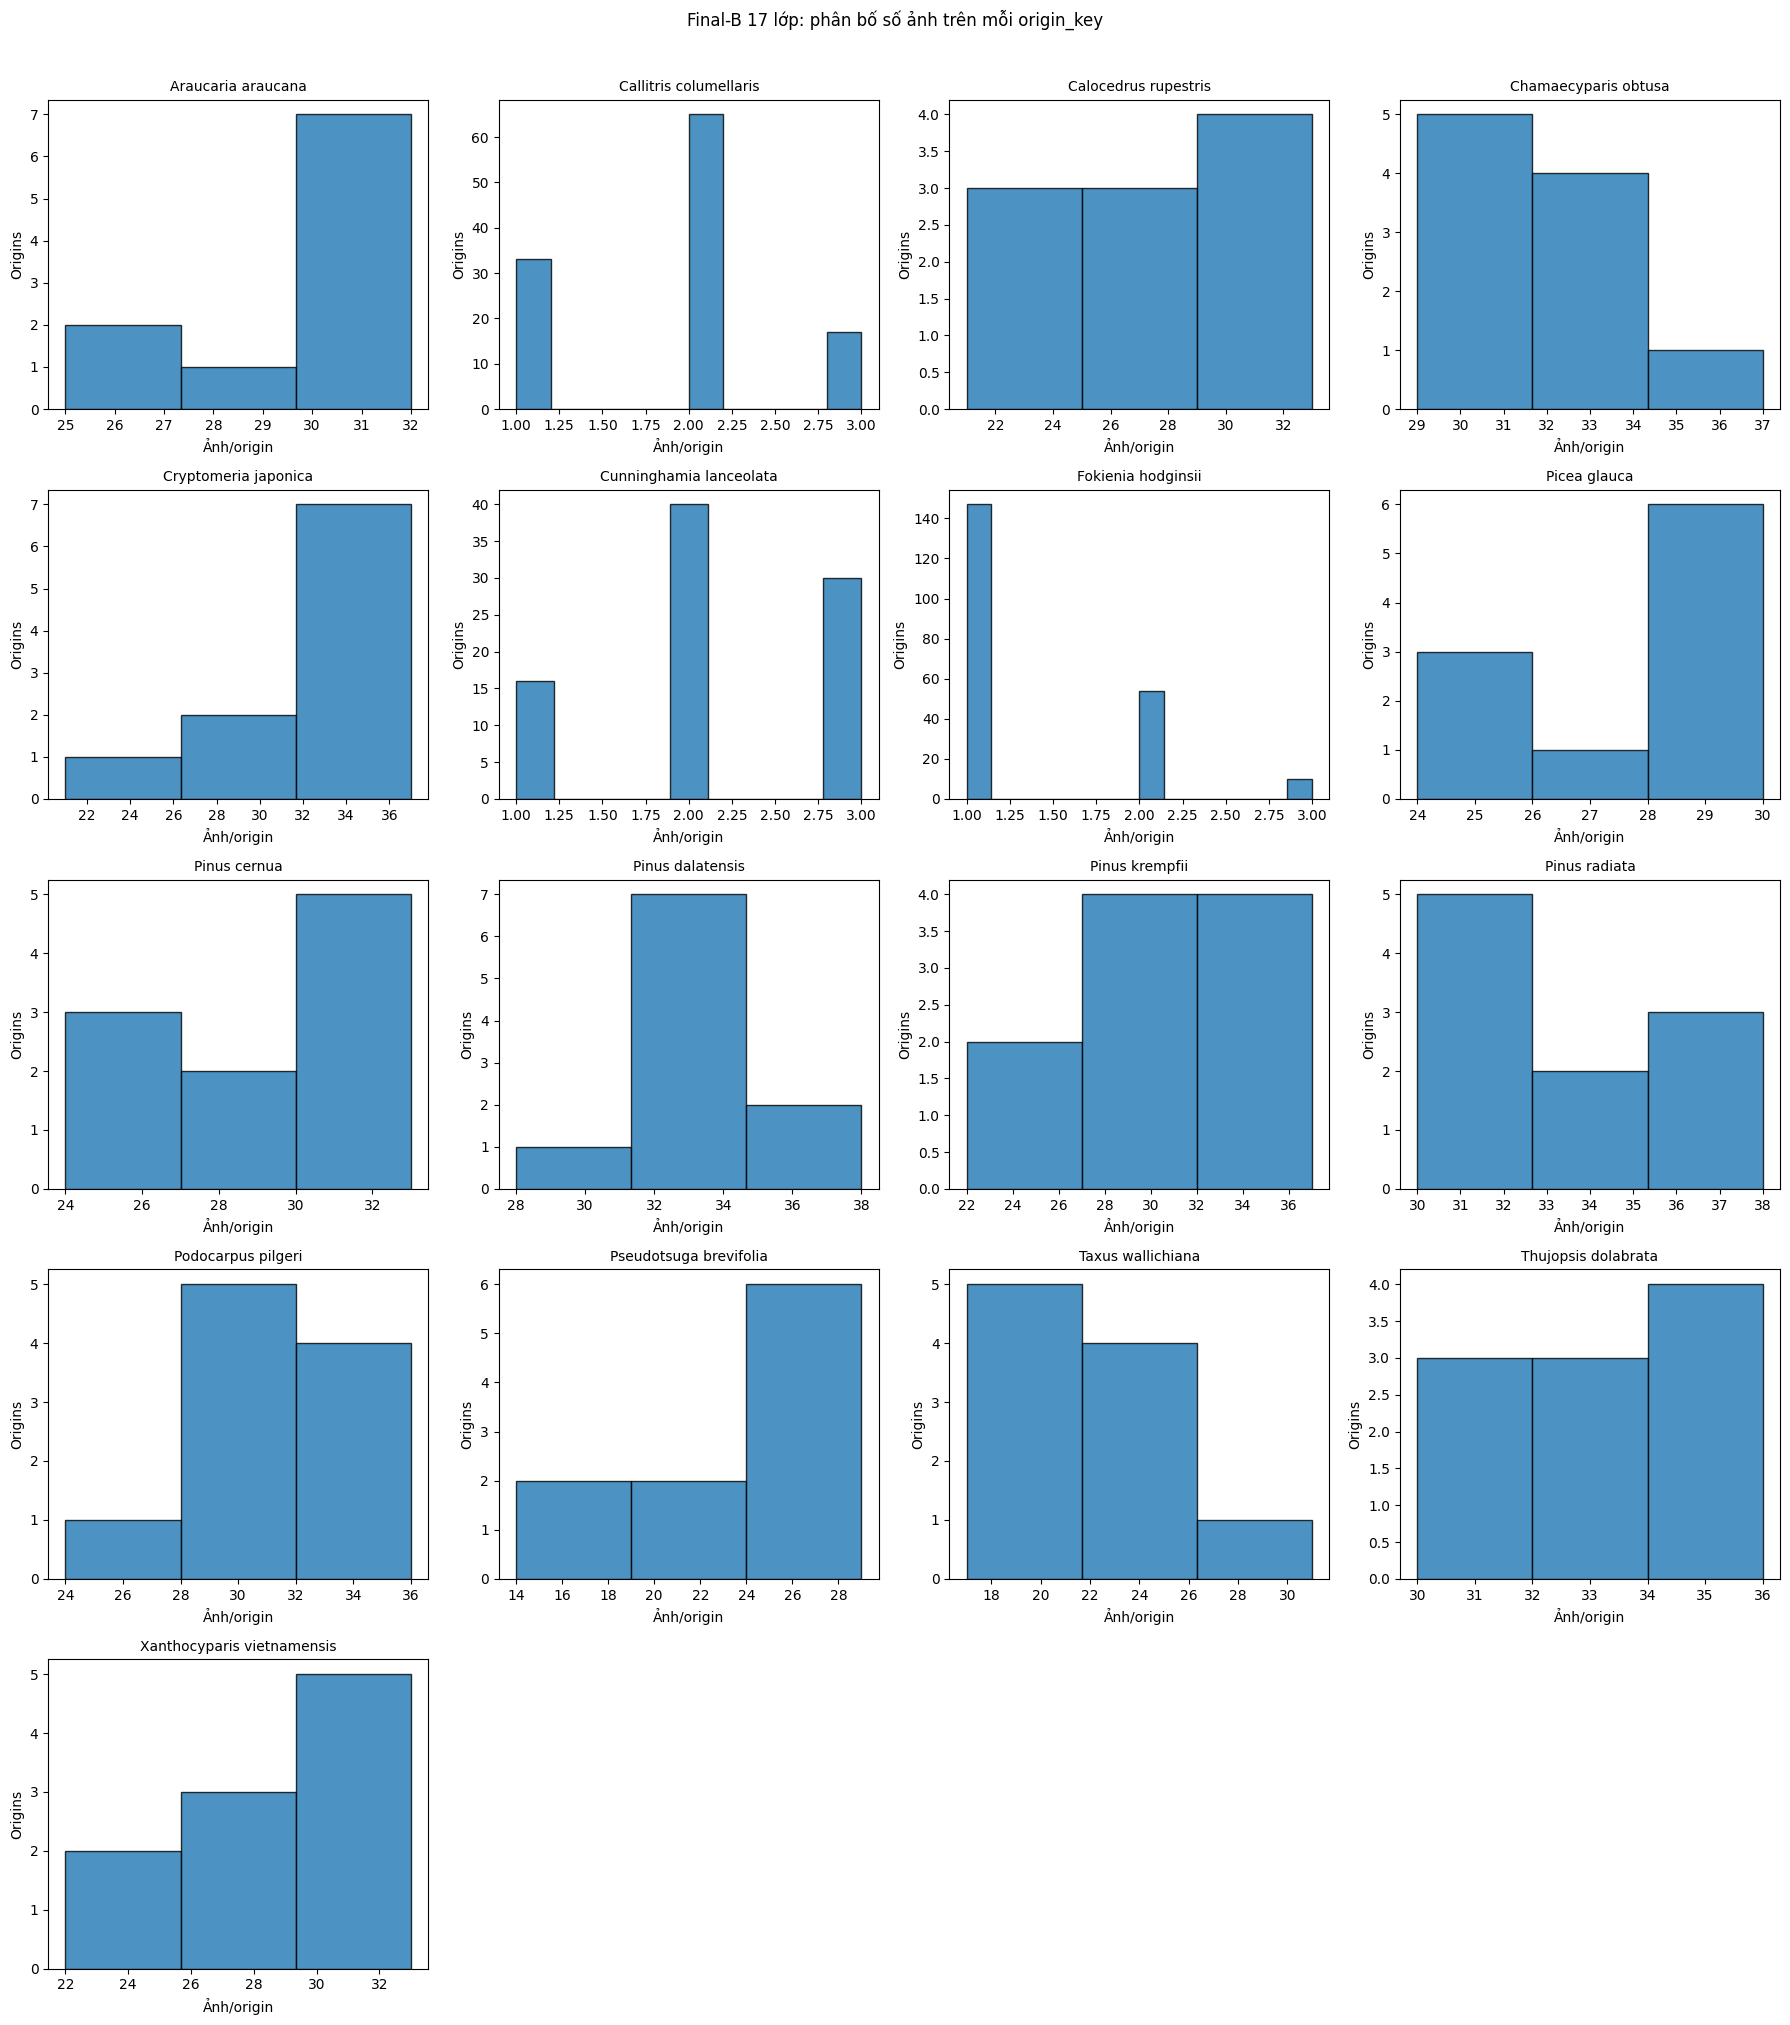

### Loài có phân bố bất thường theo quy tắc IQR

,is_final17,class_name,n_origins,total_images,min_images_per_origin,median_images_per_origin,mean_images_per_origin,max_images_per_origin,std_images_per_origin,n_origins_iqr_outlier,median_images_per_origin_iqr_outlier,distribution_outlier
4,True,Callitris columellaris,115,214,1,2.0,1.860870,3,0.647356,True,True,True
8,True,Cunninghamia lanceolata,86,186,1,2.0,2.162791,3,0.717192,True,True,True
9,True,Fokienia hodginsii,211,285,1,1.0,1.350711,3,0.569241,True,True,True


In [19]:
def safe_slug(text):
    ascii_text = unicodedata.normalize('NFKD', text).encode(
        'ascii', 'ignore'
    ).decode('ascii')
    return re.sub(r'[^a-zA-Z0-9]+', '-', ascii_text).strip('-').lower()


species_stats = (
    origins.groupby(['is_final17', 'class_name'])['n_images']
    .agg(
        n_origins='size',
        total_images='sum',
        min_images_per_origin='min',
        median_images_per_origin='median',
        mean_images_per_origin='mean',
        max_images_per_origin='max',
        std_images_per_origin='std',
    )
    .reset_index()
)

final_stats = species_stats[species_stats['is_final17']].copy()
for metric in ['n_origins', 'median_images_per_origin']:
    q1 = final_stats[metric].quantile(0.25)
    q3 = final_stats[metric].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    final_stats[f'{metric}_iqr_outlier'] = ~final_stats[metric].between(
        lower, upper
    )
final_stats['distribution_outlier'] = (
    final_stats['n_origins_iqr_outlier']
    | final_stats['median_images_per_origin_iqr_outlier']
)
species_stats = species_stats.merge(
    final_stats[
        [
            'class_name',
            'n_origins_iqr_outlier',
            'median_images_per_origin_iqr_outlier',
            'distribution_outlier',
        ]
    ],
    on='class_name',
    how='left',
)
display(
    species_stats.sort_values(
        ['is_final17', 'median_images_per_origin'], ascending=[False, True]
    )
)

for class_name, group in origins.groupby('class_name', sort=True):
    fig, ax = plt.subplots(figsize=(6.4, 4.2))
    bins = min(30, max(1, int(math.sqrt(len(group)))))
    ax.hist(group['n_images'], bins=bins, edgecolor='black', alpha=0.8)
    ax.axvline(
        group['n_images'].median(), color='crimson', linestyle='--',
        label=f'Median={group["n_images"].median():.1f}'
    )
    ax.set_title(class_name)
    ax.set_xlabel('Số ảnh trên mỗi origin_key')
    ax.set_ylabel('Số origin_key')
    ax.legend()
    fig.tight_layout()
    fig.savefig(
        HIST_BY_SPECIES_DIR / f'{safe_slug(class_name)}.png',
        dpi=200, bbox_inches='tight'
    )
    plt.close(fig)

final_classes = sorted(origins.loc[origins['is_final17'], 'class_name'].unique())
ncols = 4
nrows = math.ceil(len(final_classes) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4 * nrows))
for ax, class_name in zip(axes.flat, final_classes):
    values = origins.loc[
        origins['class_name'].eq(class_name), 'n_images'
    ]
    bins = min(30, max(1, int(math.sqrt(len(values)))))
    ax.hist(values, bins=bins, edgecolor='black', alpha=0.8)
    ax.set_title(class_name, fontsize=10)
    ax.set_xlabel('Ảnh/origin')
    ax.set_ylabel('Origins')
for ax in axes.flat[len(final_classes):]:
    ax.axis('off')
fig.suptitle('Final-B 17 lớp: phân bố số ảnh trên mỗi origin_key', y=1.01)
fig.tight_layout()
fig.savefig(HIST_DIR / 'final17_images_per_origin_grid.png', dpi=220, bbox_inches='tight')
plt.show()

outlier_species = final_stats[final_stats['distribution_outlier']].copy()
display(Markdown('### Loài có phân bố bất thường theo quy tắc IQR'))
display(outlier_species)


## 3.5. Mã số xuất hiện ở nhiều loài

Kiểm tra dùng `sample_number` đã chuẩn hóa, bỏ tên lớp và view number. Kết quả được tách thành hai bảng **không loại trừ nhau**: (1) cùng số, khác loài và cùng quy ước parse — bằng chứng trực tiếp rằng số bị dùng lại trong namespace đó; (2) cùng số nhưng khác quy ước parse — đối chiếu cần xem thêm, không được cộng như một loại bằng chứng độc lập. Bảng tổng quan ghi rõ hai cờ này cho từng số.


In [20]:
numeric_origins = origins.dropna(subset=['sample_number']).copy()

same_convention_code_reuse = (
    numeric_origins.groupby(['sample_number', 'parse_rule'])
    .agg(
        n_species=('class_name', 'nunique'),
        species=('class_name', lambda values: ' | '.join(sorted(set(values)))),
        n_origin_keys=('origin_key', 'nunique'),
        example_origin_keys=(
            'origin_key', lambda values: ' | '.join(sorted(set(values))[:8])
        ),
    )
    .reset_index()
)
same_convention_code_reuse = same_convention_code_reuse[
    same_convention_code_reuse['n_species'] > 1
].copy()
same_convention_code_reuse.insert(
    2, 'evidence_type', 'CONFIRMED_SAME_NAMING_CONVENTION'
)

mixed_rows = []
for sample_number, group in numeric_origins.groupby('sample_number'):
    if group['class_name'].nunique() < 2 or group['parse_rule'].nunique() < 2:
        continue
    rule_species = []
    for parse_rule, rule_group in group.groupby('parse_rule'):
        rule_species.append(
            f"{parse_rule}: {', '.join(sorted(rule_group['class_name'].unique()))}"
        )
    mixed_rows.append({
        'sample_number': int(sample_number),
        'evidence_type': 'MIXED_NAMING_CONVENTION_REVIEW',
        'n_parse_rules': int(group['parse_rule'].nunique()),
        'parse_rules': ' | '.join(sorted(group['parse_rule'].unique())),
        'n_species': int(group['class_name'].nunique()),
        'species_by_parse_rule': ' || '.join(rule_species),
        'example_origin_keys': ' | '.join(
            sorted(group['origin_key'].unique())[:8]
        ),
    })
mixed_convention_code_matches = pd.DataFrame(mixed_rows)

code_species = (
    numeric_origins.groupby('sample_number')
    .agg(
        n_species=('class_name', 'nunique'),
        species=('class_name', lambda values: ' | '.join(sorted(set(values)))),
        n_parse_rules=('parse_rule', 'nunique'),
        parse_rules=('parse_rule', lambda values: ' | '.join(sorted(set(values)))),
        n_origin_keys=('origin_key', 'nunique'),
        example_origin_keys=(
            'origin_key', lambda values: ' | '.join(sorted(set(values))[:8])
        ),
    )
    .reset_index()
)
cross_species_codes = code_species[code_species['n_species'] > 1].copy()
confirmed_numbers = set(same_convention_code_reuse['sample_number'])
mixed_numbers = set(mixed_convention_code_matches['sample_number'])
cross_species_codes.insert(
    1, 'confirmed_same_convention',
    cross_species_codes['sample_number'].isin(confirmed_numbers),
)
cross_species_codes.insert(
    2, 'also_mixed_convention',
    cross_species_codes['sample_number'].isin(mixed_numbers),
)

display(Markdown('### 3.5a — Trùng mã trong cùng quy ước đặt tên'))
display(same_convention_code_reuse)
display(Markdown('### 3.5b — Số trùng qua nhiều quy ước đặt tên'))
display(mixed_convention_code_matches)
display(Markdown('### 3.5c — Bảng tổng quan, không cộng chồng hai nhóm'))
display(cross_species_codes)
print(
    f'{len(same_convention_code_reuse)} mã được xác nhận trùng giữa loài '
    'trong cùng quy ước; '
    f'{len(mixed_convention_code_matches)} mã đồng thời khớp qua nhiều '
    'quy ước và cần ghi chú riêng.'
)


### 3.5a — Trùng mã trong cùng quy ước đặt tên

,sample_number,parse_rule,evidence_type,n_species,species,n_origin_keys,example_origin_keys
10,10,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::10 | Cunninghamia lanc...
12,11,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::11 | Cunninghamia lanc...
14,12,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::12 | Cunninghamia lanc...
16,13,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::13 | Cunninghamia lanc...
18,14,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::14 | Cunninghamia lanc...
...,...,...,...,...,...,...,...
191,181,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::181 | Cunninghamia lan...
192,182,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::182 | Cunninghamia lan...
193,183,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::183 | Cunninghamia lan...
194,184,pure_numeric_filename,CONFIRMED_SAME_NAMING_CONVENTION,2,Callitris columellaris | Cunninghamia lanceolata,2,Callitris columellaris::184 | Cunninghamia lan...


### 3.5b — Số trùng qua nhiều quy ước đặt tên

,sample_number,evidence_type,n_parse_rules,parse_rules,n_species,species_by_parse_rule,example_origin_keys
0,10,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::10 | Cunninghamia lanc...
1,11,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::11 | Cunninghamia lanc...
2,12,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::12 | Cunninghamia lanc...
3,13,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::13 | Cunninghamia lanc...
4,14,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::14 | Cunninghamia lanc...
5,15,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::15 | Cunninghamia lanc...
6,16,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::16 | Cunninghamia lanc...
7,17,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::17 | Cunninghamia lanc...
8,18,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::18 | Cunninghamia lanc...
9,19,MIXED_NAMING_CONVENTION_REVIEW,2,pure_numeric_filename | text_with_trailing_number,3,"pure_numeric_filename: Callitris columellaris,...",Callitris columellaris::19 | Cunninghamia lanc...


### 3.5c — Bảng tổng quan, không cộng chồng hai nhóm

,sample_number,confirmed_same_convention,also_mixed_convention,n_species,species,n_parse_rules,parse_rules,n_origin_keys,example_origin_keys
10,10,True,True,3,Callitris columellaris | Cunninghamia lanceola...,2,pure_numeric_filename | text_with_trailing_number,4,Callitris columellaris::10 | Cunninghamia lanc...
11,11,True,True,3,Callitris columellaris | Cunninghamia lanceola...,2,pure_numeric_filename | text_with_trailing_number,4,Callitris columellaris::11 | Cunninghamia lanc...
12,12,True,True,3,Callitris columellaris | Cunninghamia lanceola...,2,pure_numeric_filename | text_with_trailing_number,4,Callitris columellaris::12 | Cunninghamia lanc...
13,13,True,True,3,Callitris columellaris | Cunninghamia lanceola...,2,pure_numeric_filename | text_with_trailing_number,3,Callitris columellaris::13 | Cunninghamia lanc...
14,14,True,True,3,Callitris columellaris | Cunninghamia lanceola...,2,pure_numeric_filename | text_with_trailing_number,3,Callitris columellaris::14 | Cunninghamia lanc...
...,...,...,...,...,...,...,...,...,...
181,181,True,False,2,Callitris columellaris | Cunninghamia lanceolata,1,pure_numeric_filename,2,Callitris columellaris::181 | Cunninghamia lan...
182,182,True,False,2,Callitris columellaris | Cunninghamia lanceolata,1,pure_numeric_filename,2,Callitris columellaris::182 | Cunninghamia lan...
183,183,True,False,2,Callitris columellaris | Cunninghamia lanceolata,1,pure_numeric_filename,2,Callitris columellaris::183 | Cunninghamia lan...
184,184,True,False,2,Callitris columellaris | Cunninghamia lanceolata,1,pure_numeric_filename,2,Callitris columellaris::184 | Cunninghamia lan...


86 mã được xác nhận trùng giữa loài trong cùng quy ước; 10 mã đồng thời khớp qua nhiều quy ước và cần ghi chú riêng.


## 3.6. Mẫu 20 origin để đối chiếu sổ phòng

Form gồm hai origin `3325.1`/`3325.2` bắt buộc và 18 origin lấy ngẫu nhiên bằng seed 42. Đường dẫn `data/task-B-clean` trong manifest chỉ là đường dẫn lịch sử: thư mục này đã bị xóa sau khi materialize. Cell kế tiếp ánh xạ từng dòng sang `data/task-B-group-split` (17 lớp hiện hành) hoặc `data/task-B-group-split-excluded` (3 lớp đã loại), kể cả file có hậu tố chống trùng basename. Điền các cột `lab_book_*`, đổi `verification_status` thành `VERIFIED`, rồi chạy lại notebook; các trường đã điền không bị ghi đè.


In [21]:
mandatory = origins[origins['sample_number'].eq(3325)].copy()
assert len(mandatory) == 2, 'Không tìm thấy đúng cặp 3325.1 và 3325.2'
remaining_pool = origins[~origins['origin_key'].isin(mandatory['origin_key'])]
random_sample = remaining_pool.sample(n=18, random_state=RANDOM_SEED)
sample20 = pd.concat([mandatory, random_sample], ignore_index=True)
sample20['selection_reason'] = np.where(
    sample20['sample_number'].eq(3325),
    'required_3325_pair',
    f'random_seed_{RANDOM_SEED}',
)
sample20 = sample20.sort_values(
    ['selection_reason', 'class_name', 'origin_key']
).reset_index(drop=True)
sample20.insert(0, 'selection_order', np.arange(1, len(sample20) + 1))

manual_columns = [
    'selection_order', 'selection_reason', 'class_name', 'origin_key',
    'sample_number', 'view_number', 'coarse_origin_key', 'n_images',
    'example_filenames', 'example_paths', 'lab_book_specimen_id',
    'lab_book_block_id', 'lab_book_description',
    'same_physical_block_as_other_rows', 'checked_by', 'checked_date',
    'evidence_reference', 'verification_status', 'notes',
]
template = sample20.reindex(columns=manual_columns).copy()
for column in [
    'lab_book_specimen_id', 'lab_book_block_id', 'lab_book_description',
    'same_physical_block_as_other_rows', 'checked_by', 'checked_date',
    'evidence_reference', 'notes',
]:
    template[column] = ''
template['verification_status'] = 'PENDING_LAB_BOOK'

if not MANUAL_LOOKUP_PATH.exists():
    template.to_csv(MANUAL_LOOKUP_PATH, index=False)
    print(f'Created manual form: {MANUAL_LOOKUP_PATH.relative_to(ROOT)}')
else:
    print(f'Preserved existing manual form: {MANUAL_LOOKUP_PATH.relative_to(ROOT)}')
manual_lookup = pd.read_csv(MANUAL_LOOKUP_PATH, keep_default_na=False)
assert len(manual_lookup) == 20
assert set(template['origin_key']) == set(manual_lookup['origin_key'])
display(manual_lookup)


Preserved existing manual form: artifacts/phase_1b/origin_key_audit/sample_book_lookup_20.csv


,selection_order,selection_reason,class_name,origin_key,sample_number,view_number,coarse_origin_key,n_images,example_filenames,historical_task_B_clean_paths,...,same_physical_block_as_other_rows,checked_by,checked_date,evidence_reference,verification_status,notes,resolved_image_count,current_data_root,current_example_paths,all_selected_images_md5_verified
0,1,random_seed_42,Callitris columellaris,Callitris columellaris::10,10,,Callitris columellaris::10,2,10.png | 10.png,data/task-B-clean/train/Callitris columellaris...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/train/Callitris colume...,True
1,2,random_seed_42,Callitris columellaris,Callitris columellaris::136,136,,Callitris columellaris::136,2,136.png | 136.png,data/task-B-clean/train/Callitris columellaris...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/train/Callitris colume...,True
2,3,random_seed_42,Callitris columellaris,Callitris columellaris::15,15,,Callitris columellaris::15,2,15.png | 15.png,data/task-B-clean/train/Callitris columellaris...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/val/Callitris columell...,True
3,4,random_seed_42,Callitris columellaris,Callitris columellaris::155,155,,Callitris columellaris::155,2,155.png | 155.png,data/task-B-clean/train/Callitris columellaris...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/train/Callitris colume...,True
4,5,random_seed_42,Callitris columellaris,Callitris columellaris::16,16,,Callitris columellaris::16,2,16.png | 16.png,data/task-B-clean/train/Callitris columellaris...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/train/Callitris colume...,True
5,6,random_seed_42,Calocedrus rupestris,Calocedrus rupestris::3342. Calocedrus rupestr...,3342,6,Calocedrus rupestris::3342,21,3342. Calocedrus rupestris.6.(153).png | 3342....,data/task-B-clean/train/Calocedrus rupestris/3...,...,,,,,PENDING_LAB_BOOK,,21,data/task-B-group-split,data/task-B-group-split/train/Calocedrus rupes...,True
6,7,random_seed_42,Cunninghamia lanceolata,Cunninghamia lanceolata::110,110,,Cunninghamia lanceolata::110,2,110.png | 110.png,data/task-B-clean/train/Cunninghamia lanceolat...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/test/Cunninghamia lanc...,True
7,8,random_seed_42,Cunninghamia lanceolata,Cunninghamia lanceolata::144,144,,Cunninghamia lanceolata::144,3,144.png | 144.png | 144.png,data/task-B-clean/train/Cunninghamia lanceolat...,...,,,,,PENDING_LAB_BOOK,,3,data/task-B-group-split,data/task-B-group-split/train/Cunninghamia lan...,True
8,9,random_seed_42,Cunninghamia lanceolata,Cunninghamia lanceolata::156,156,,Cunninghamia lanceolata::156,2,156.png | 156.png,data/task-B-clean/train/Cunninghamia lanceolat...,...,,,,,PENDING_LAB_BOOK,,2,data/task-B-group-split,data/task-B-group-split/test/Cunninghamia lanc...,True
9,10,random_seed_42,Cunninghamia lanceolata,Cunninghamia lanceolata::177,177,,Cunninghamia lanceolata::177,1,177.png,data/task-B-clean/train/Cunninghamia lanceolat...,...,,,,,PENDING_LAB_BOOK,,1,data/task-B-group-split,data/task-B-group-split/train/Cunninghamia lan...,True


In [22]:
import hashlib
from PIL import Image, ImageDraw, ImageOps

GROUP_SPLIT_ROOT = ROOT / 'data' / 'task-B-group-split'
EXCLUDED_SPLIT_ROOT = ROOT / 'data' / 'task-B-group-split-excluded'
CONTACT_SHEET_PATH = ARTIFACT_DIR / 'manual_lookup_contact_sheet_examples.png'
PAIR_3325_SHEET_PATH = ARTIFACT_DIR / 'manual_lookup_3325_pair_contact_sheet.png'

def materialized_image_path(row):
    root = (
        EXCLUDED_SPLIT_ROOT
        if row.class_name in EXCLUDED_CLASSES
        else GROUP_SPLIT_ROOT
    )
    class_dir = root / row.new_split / row.class_name
    source_name = Path(row.filename)
    renamed = class_dir / (
        f'{source_name.stem}__from-{row.old_split}__'
        f'{str(row.md5)[:8]}{source_name.suffix}'
    )
    plain = class_dir / source_name.name
    if renamed.exists():
        return renamed
    if plain.exists():
        return plain
    return None

resolved_manifest = manifest.copy()
resolved_manifest['current_path_obj'] = [
    materialized_image_path(row)
    for row in resolved_manifest.itertuples(index=False)
]
resolved_manifest['current_path'] = resolved_manifest['current_path_obj'].map(
    lambda path: str(path.relative_to(ROOT)) if path else ''
)
resolved_manifest['current_root'] = np.where(
    resolved_manifest['class_name'].isin(EXCLUDED_CLASSES),
    'data/task-B-group-split-excluded',
    'data/task-B-group-split',
)
unresolved = resolved_manifest[resolved_manifest['current_path'].eq('')]
assert unresolved.empty, (
    f'Không ánh xạ được {len(unresolved)} ảnh sang materialized split'
)

def md5_file(path, chunk_size=1024 * 1024):
    digest = hashlib.md5()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

sample_keys = set(sample20['origin_key'])
sample_images = resolved_manifest[
    resolved_manifest['origin_key'].isin(sample_keys)
].copy()
sample_images['actual_md5'] = sample_images['current_path_obj'].map(md5_file)
sample_images['md5_matches_manifest'] = (
    sample_images['actual_md5'].str.lower()
    == sample_images['md5'].astype(str).str.lower()
)
assert sample_images['md5_matches_manifest'].all(), (
    'Có ảnh đối chiếu không khớp MD5 với manifest task-B-clean'
)

resolved_by_origin = (
    sample_images.groupby('origin_key', sort=False)
    .agg(
        resolved_image_count=('current_path', 'size'),
        current_data_root=('current_root', lambda s: ' | '.join(sorted(set(s)))),
        current_example_paths=(
            'current_path', lambda s: ' | '.join(s.astype(str).head(5))
        ),
        all_selected_images_md5_verified=(
            'md5_matches_manifest', 'all'
        ),
    )
    .reset_index()
)

generated_columns = [
    'resolved_image_count', 'current_data_root', 'current_example_paths',
    'all_selected_images_md5_verified',
]
lookup_base = manual_lookup.drop(columns=generated_columns, errors='ignore').copy()
if 'example_paths' in lookup_base.columns:
    lookup_base = lookup_base.rename(
        columns={'example_paths': 'historical_task_B_clean_paths'}
    )
manual_lookup = lookup_base.merge(
    resolved_by_origin, on='origin_key', how='left', validate='one_to_one'
)
assert manual_lookup['resolved_image_count'].eq(manual_lookup['n_images']).all()
manual_lookup.to_csv(MANUAL_LOOKUP_PATH, index=False)

def make_contact_sheet(origin_keys, output_path, images_per_origin=3):
    tile_w, tile_h, label_h = 300, 220, 62
    rows = []
    for origin_key in origin_keys:
        group = sample_images[sample_images['origin_key'].eq(origin_key)].head(
            images_per_origin
        )
        rows.append((origin_key, group))
    canvas = Image.new(
        'RGB',
        (images_per_origin * tile_w, len(rows) * (tile_h + label_h)),
        'white',
    )
    draw = ImageDraw.Draw(canvas)
    for row_index, (origin_key, group) in enumerate(rows):
        y0 = row_index * (tile_h + label_h)
        class_name = group.iloc[0]['class_name']
        short_origin = str(origin_key).split('::', 1)[-1]
        draw.text((8, y0 + 5), f'{class_name} | {short_origin}', fill='black')
        draw.text(
            (8, y0 + 27),
            f"{group.iloc[0]['current_root']} | manifest MD5: OK",
            fill='#333333',
        )
        for col_index, image_row in enumerate(group.itertuples(index=False)):
            with Image.open(image_row.current_path_obj) as image:
                image = ImageOps.exif_transpose(image).convert('RGB')
                image.thumbnail((tile_w - 12, tile_h - 12))
                x = col_index * tile_w + (tile_w - image.width) // 2
                y = y0 + label_h + (tile_h - image.height) // 2
                canvas.paste(image, (x, y))
    canvas.save(output_path, quality=92)
    return output_path

distinct_examples = (
    sample20[~sample20['sample_number'].eq(3325)]
    .drop_duplicates('class_name')
    .head(4)['origin_key']
    .tolist()
)
pair_keys = sample20[sample20['sample_number'].eq(3325)]['origin_key'].tolist()
make_contact_sheet(distinct_examples + pair_keys, CONTACT_SHEET_PATH)
make_contact_sheet(pair_keys, PAIR_3325_SHEET_PATH, images_per_origin=4)
resolved_manifest.drop(columns=['current_path_obj']).to_csv(
    ARTIFACT_DIR / 'image_path_resolution.csv', index=False
)

print(f'Resolved current images: {len(resolved_manifest):,}/{len(manifest):,}')
print(f'Current Final-B root: {GROUP_SPLIT_ROOT.relative_to(ROOT)}')
print(f'Excluded-class fallback: {EXCLUDED_SPLIT_ROOT.relative_to(ROOT)}')
print(f'Sampled images verified by MD5: {len(sample_images):,}')
display(manual_lookup[[
    'selection_order', 'class_name', 'origin_key', 'resolved_image_count',
    'current_data_root', 'all_selected_images_md5_verified',
]])


Resolved current images: 5,572/5,572
Current Final-B root: data/task-B-group-split
Excluded-class fallback: data/task-B-group-split-excluded
Sampled images verified by MD5: 356


,selection_order,class_name,origin_key,resolved_image_count,current_data_root,all_selected_images_md5_verified
0,1,Callitris columellaris,Callitris columellaris::10,2,data/task-B-group-split,True
1,2,Callitris columellaris,Callitris columellaris::136,2,data/task-B-group-split,True
2,3,Callitris columellaris,Callitris columellaris::15,2,data/task-B-group-split,True
3,4,Callitris columellaris,Callitris columellaris::155,2,data/task-B-group-split,True
4,5,Callitris columellaris,Callitris columellaris::16,2,data/task-B-group-split,True
5,6,Calocedrus rupestris,Calocedrus rupestris::3342. Calocedrus rupestr...,21,data/task-B-group-split,True
6,7,Cunninghamia lanceolata,Cunninghamia lanceolata::110,2,data/task-B-group-split,True
7,8,Cunninghamia lanceolata,Cunninghamia lanceolata::144,3,data/task-B-group-split,True
8,9,Cunninghamia lanceolata,Cunninghamia lanceolata::156,2,data/task-B-group-split,True
9,10,Cunninghamia lanceolata,Cunninghamia lanceolata::177,1,data/task-B-group-split,True


### Kiểm tra các cặp suffix khác ngoài ví dụ 3325

Cell này tìm **toàn bộ** nhóm số có ít nhất hai `origin_key` dạng `{sample}.{view}`, loại riêng ví dụ 3325, rồi lấy hai suffix nhỏ nhất của mỗi nhóm để xem trực tiếp. Mỗi cột là một `origin_key`, mỗi ô dùng một ảnh đại diện đã đối chiếu MD5 với manifest. Sự giống hoặc khác về hình ảnh chỉ hỗ trợ tra sổ; không thay thế định danh khối gỗ của phòng.


Other same-sample groups checked: 15; representative images MD5-verified: 30


,class_name,sample_number,available_suffix_count,suffix_a,origin_key_a,image_path_a,suffix_b,origin_key_b,image_path_b,representative_images_md5_verified
0,Araucaria araucana,3351,10,1,Araucaria araucana::3351. Araucaria araucana.1.,data/task-B-group-split/train/Araucaria arauca...,2,Araucaria araucana::3351. Araucaria araucana.2.,data/task-B-group-split/train/Araucaria arauca...,True
1,Calocedrus rupestris,3342,10,1,Calocedrus rupestris::3342. Calocedrus rupestr...,data/task-B-group-split/train/Calocedrus rupes...,2,Calocedrus rupestris::3342. Calocedrus rupestr...,data/task-B-group-split/val/Calocedrus rupestr...,True
2,Chamaecyparis obtusa,3364,10,1,Chamaecyparis obtusa::3364. Chamaecyparis obtu...,data/task-B-group-split/train/Chamaecyparis ob...,2,Chamaecyparis obtusa::3364. Chamaecyparis obtu...,data/task-B-group-split/val/Chamaecyparis obtu...,True
3,Cryptomeria japonica,3350,7,1,Cryptomeria japonica::3350. Cryptomeria japoni...,data/task-B-group-split/train/Cryptomeria japo...,2,Cryptomeria japonica::3350. Cryptomeria japoni...,data/task-B-group-split/val/Cryptomeria japoni...,True
4,Cupressus funebris (Cupressus pendula),3314,2,1,Cupressus funebris (Cupressus pendula)::Cupres...,data/task-B-group-split-excluded/test/Cupressu...,2,Cupressus funebris (Cupressus pendula)::Cupres...,data/task-B-group-split-excluded/train/Cupress...,True
5,Picea glauca,3378,9,1,Picea glauca::3378. Picea glauca.1,data/task-B-group-split/train/Picea glauca/337...,3,Picea glauca::3378. Picea glauca.3,data/task-B-group-split/val/Picea glauca/3378....,True
6,Pinus cernua,3385,10,1,Pinus cernua::3385. Pinus cernua.1,data/task-B-group-split/train/Pinus cernua/338...,2,Pinus cernua::3385. Pinus cernua.2,data/task-B-group-split/train/Pinus cernua/338...,True
7,Pinus dalatensis,3393,10,1,Pinus dalatensis::3393. Pinus dalatensis.1,data/task-B-group-split/train/Pinus dalatensis...,2,Pinus dalatensis::3393. Pinus dalatensis.2,data/task-B-group-split/test/Pinus dalatensis/...,True
8,Pinus krempfii,3384,9,1,Pinus krempfii::3384. Pinus krempfii.1,data/task-B-group-split/train/Pinus krempfii/3...,3,Pinus krempfii::3384. Pinus krempfii.3,data/task-B-group-split/train/Pinus krempfii/3...,True
9,Pinus radiata,3379,10,1,Pinus radiata::3379. Pinus radiata.1,data/task-B-group-split/val/Pinus radiata/3379...,2,Pinus radiata::3379. Pinus radiata.2,data/task-B-group-split/val/Pinus radiata/3379...,True


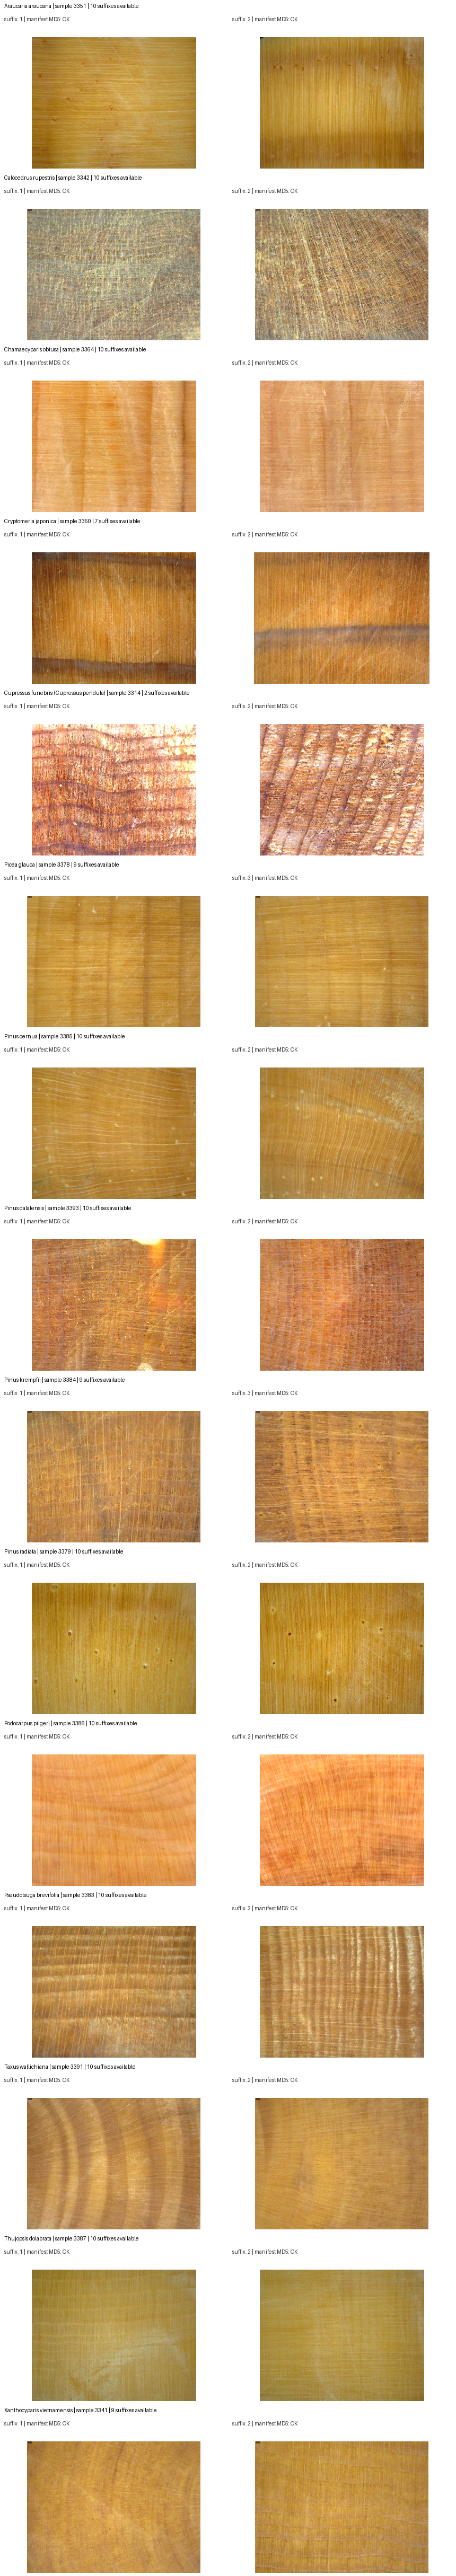

In [23]:
from IPython.display import Image as DisplayImage

OTHER_PAIR_SHEET_PATH = (
    ARTIFACT_DIR / 'manual_lookup_other_suffix_pairs.png'
)
OTHER_PAIR_TABLE_PATH = (
    ARTIFACT_DIR / 'other_suffix_pair_examples.csv'
)

numeric_origins_for_pairs = origins[
    origins['numeric_dot_numeric']
    & origins['sample_number'].ne(3325)
].copy()
pair_group_sizes = (
    numeric_origins_for_pairs.groupby(['class_name', 'sample_number'])
    ['origin_key'].nunique()
)
eligible_pair_groups = pair_group_sizes[pair_group_sizes >= 2]

other_pair_rows = []
other_pair_images = []
for class_name, sample_number in eligible_pair_groups.index:
    candidates = numeric_origins_for_pairs[
        numeric_origins_for_pairs['class_name'].eq(class_name)
        & numeric_origins_for_pairs['sample_number'].eq(sample_number)
    ].sort_values(['view_number', 'origin_key']).head(2)
    selected = []
    for origin in candidates.itertuples(index=False):
        image_row = resolved_manifest[
            resolved_manifest['origin_key'].eq(origin.origin_key)
        ].sort_values(['new_split', 'filename']).iloc[0]
        actual_md5 = md5_file(image_row['current_path_obj'])
        assert actual_md5.lower() == str(image_row['md5']).lower()
        selected.append((origin, image_row))
        other_pair_images.append(image_row)
    left_origin, left_image = selected[0]
    right_origin, right_image = selected[1]
    other_pair_rows.append({
        'class_name': class_name,
        'sample_number': int(sample_number),
        'available_suffix_count': int(eligible_pair_groups.loc[(class_name, sample_number)]),
        'suffix_a': int(left_origin.view_number),
        'origin_key_a': left_origin.origin_key,
        'image_path_a': left_image['current_path'],
        'suffix_b': int(right_origin.view_number),
        'origin_key_b': right_origin.origin_key,
        'image_path_b': right_image['current_path'],
        'representative_images_md5_verified': True,
    })

other_pair_examples = pd.DataFrame(other_pair_rows).sort_values(
    ['class_name', 'sample_number']
).reset_index(drop=True)
other_pair_examples.to_csv(OTHER_PAIR_TABLE_PATH, index=False)

def make_other_pair_sheet(pair_rows, output_path):
    tile_w, tile_h, header_h = 430, 260, 64
    canvas = Image.new(
        'RGB', (tile_w * 2, len(pair_rows) * (tile_h + header_h)), 'white'
    )
    draw = ImageDraw.Draw(canvas)
    for row_index, row in enumerate(pair_rows):
        y0 = row_index * (tile_h + header_h)
        draw.text(
            (8, y0 + 5),
            f"{row['class_name']} | sample {row['sample_number']} | "
            f"{row['available_suffix_count']} suffixes available",
            fill='black',
        )
        for col_index, side in enumerate(('a', 'b')):
            path = ROOT / row[f'image_path_{side}']
            draw.text(
                (col_index * tile_w + 8, y0 + 30),
                f"suffix .{row[f'suffix_{side}']} | manifest MD5: OK",
                fill='#333333',
            )
            with Image.open(path) as image:
                image = ImageOps.exif_transpose(image).convert('RGB')
                image.thumbnail((tile_w - 16, tile_h - 12))
                x = col_index * tile_w + (tile_w - image.width) // 2
                y = y0 + header_h + (tile_h - image.height) // 2
                canvas.paste(image, (x, y))
    canvas.save(output_path, quality=92)
    return output_path

make_other_pair_sheet(other_pair_rows, OTHER_PAIR_SHEET_PATH)
print(
    f'Other same-sample groups checked: {len(other_pair_examples)}; '
    f'representative images MD5-verified: {len(other_pair_images)}'
)
display(other_pair_examples)
display(DisplayImage(filename=str(OTHER_PAIR_SHEET_PATH)))


## 3.7. Số origin độc lập của 17 loài và ngưỡng tối thiểu 3

Bảng tách hai mức: heuristic hiện tại và nhóm thô theo mã mẫu. Nhóm thô chỉ trở thành quyết định loại chính thức sau khi sổ phòng xác nhận rằng các suffix `.1`, `.2`, … là view của cùng khối gỗ.


In [24]:
final17 = origins[origins['is_final17']].copy()
final17_counts = (
    final17.groupby('class_name')
    .agg(
        current_origin_keys=('origin_key', 'nunique'),
        coarse_candidate_groups=('coarse_origin_key', 'nunique'),
        images=('n_images', 'sum'),
    )
    .reset_index()
)
final17_counts['below_3_current_heuristic'] = (
    final17_counts['current_origin_keys'] < MIN_INDEPENDENT_ORIGINS
)
final17_counts['below_3_if_coarse_is_specimen'] = (
    final17_counts['coarse_candidate_groups'] < MIN_INDEPENDENT_ORIGINS
)
final17_counts['criterion_action'] = np.select(
    [
        final17_counts['below_3_current_heuristic'],
        final17_counts['below_3_if_coarse_is_specimen'],
    ],
    [
        'EXCLUDE_NOW_UNDER_CURRENT_HEURISTIC',
        'PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_CONFIRMED',
    ],
    default='KEEP_UNDER_BOTH_COUNTS',
)
display(final17_counts.sort_values('coarse_candidate_groups'))
below3 = final17_counts[
    final17_counts['below_3_current_heuristic']
    | final17_counts['below_3_if_coarse_is_specimen']
].copy()
display(Markdown('### Các loài chạm tiêu chí loại ở ít nhất một cách đếm'))
display(below3)


,class_name,current_origin_keys,coarse_candidate_groups,images,below_3_current_heuristic,below_3_if_coarse_is_specimen,criterion_action
0,Araucaria araucana,10,1,293,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
14,Taxus wallichiana,10,1,223,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
13,Pseudotsuga brevifolia,10,1,235,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
12,Podocarpus pilgeri,10,1,310,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
11,Pinus radiata,10,1,331,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
10,Pinus krempfii,10,1,304,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
9,Pinus dalatensis,10,1,334,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
15,Thujopsis dolabrata,10,1,327,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
8,Pinus cernua,10,1,287,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
4,Cryptomeria japonica,10,1,320,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...


### Các loài chạm tiêu chí loại ở ít nhất một cách đếm

,class_name,current_origin_keys,coarse_candidate_groups,images,below_3_current_heuristic,below_3_if_coarse_is_specimen,criterion_action
0,Araucaria araucana,10,1,293,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
2,Calocedrus rupestris,10,1,272,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
3,Chamaecyparis obtusa,10,1,317,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
4,Cryptomeria japonica,10,1,320,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
7,Picea glauca,10,1,278,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
8,Pinus cernua,10,1,287,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
9,Pinus dalatensis,10,1,334,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
10,Pinus krempfii,10,1,304,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
11,Pinus radiata,10,1,331,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...
12,Podocarpus pilgeri,10,1,310,False,True,PENDING_LAB_BOOK_CONFIRMATION_THEN_EXCLUDE_IF_...


## Kết luận có điều kiện từ bảng sổ phòng


In [25]:
required_manual_fields = [
    'lab_book_specimen_id', 'lab_book_block_id', 'checked_by',
    'checked_date', 'evidence_reference',
]
manual_complete = manual_lookup['verification_status'].eq('VERIFIED').all()
manual_complete = manual_complete and all(
    manual_lookup[column].astype(str).str.strip().ne('').all()
    for column in required_manual_fields
)

if not manual_complete:
    conclusion = (
        '# Kết luận về ý nghĩa origin_key\n\n'
        '**CHƯA THỂ KẾT LUẬN origin_key định danh ảnh/view hay mẫu vật '
        'gỗ.** Phân tích chuỗi chỉ tạo giả thuyết; bảng 20 origin chưa '
        'được đối chiếu đầy đủ với sổ mẫu phòng. Không được dùng tên file '
        'để thay cho bước xác minh này.\n'
    )
else:
    block_reuse = (
        manual_lookup.groupby('lab_book_block_id')['origin_key'].nunique() > 1
    )
    pair3325 = manual_lookup[manual_lookup['sample_number'].astype(str).eq('3325')]
    pair_same_block = pair3325['lab_book_block_id'].nunique() == 1
    if block_reuse.any():
        answer = (
            'Trong mẫu kiểm tra, nhiều origin_key trỏ về cùng một khối gỗ; '
            'origin_key hiện tại định danh ảnh/view ở mức chi tiết hơn mẫu '
            'vật, không định danh độc lập một khúc gỗ.'
        )
    else:
        answer = (
            'Trong mẫu 20 origin chưa thấy hai origin_key dùng chung một '
            'khối gỗ. Kết quả này ủng hộ nhưng chưa chứng minh toàn bộ '
            'origin_key là định danh mẫu vật.'
        )
    pair_answer = (
        '3325.1 và 3325.2 là hai view của cùng một khối gỗ.'
        if pair_same_block
        else '3325.1 và 3325.2 được sổ phòng ghi là hai khối gỗ khác nhau.'
    )
    conclusion = (
        '# Kết luận về ý nghĩa origin_key\n\n'
        f'**{answer}**\n\n{pair_answer}\n'
    )

conclusion_path = ARTIFACT_DIR / 'conclusion_origin_key.md'
conclusion_path.write_text(conclusion, encoding='utf-8')
display(Markdown(conclusion))


# Kết luận về ý nghĩa origin_key

**CHƯA THỂ KẾT LUẬN origin_key định danh ảnh/view hay mẫu vật gỗ.** Phân tích chuỗi chỉ tạo giả thuyết; bảng 20 origin chưa được đối chiếu đầy đủ với sổ mẫu phòng. Không được dùng tên file để thay cho bước xác minh này.


## Xuất toàn bộ artifact


In [26]:
outputs = {
    'origins.csv': origins,
    'origins_final17.csv': origins[origins['is_final17']],
    'origin_string_structure_summary.csv': structure_summary,
    'origin_string_scope_summary.csv': structure_scope_summary,
    'nonconforming_origins.csv': nonconforming,
    'nonconforming_by_species.csv': nonconforming_by_species,
    'coarse_origin_summary.csv': coarse_summary,
    'species_origin_distribution.csv': species_stats,
    'distribution_outlier_species_final17.csv': outlier_species,
    'cross_species_code_reuse.csv': cross_species_codes,
    'same_convention_code_reuse.csv': same_convention_code_reuse,
    'mixed_convention_code_matches.csv': mixed_convention_code_matches,
    'final17_origin_counts.csv': final17_counts,
    'species_below_3_origin_review.csv': below3,
}
for filename, frame in outputs.items():
    frame.to_csv(ARTIFACT_DIR / filename, index=False)

run_summary = {
    'manifest': str(MANIFEST_PATH.relative_to(ROOT)),
    'images': int(len(manifest)),
    'classes_all': int(origins['class_name'].nunique()),
    'origin_keys_all': int(origins['origin_key'].nunique()),
    'classes_final17': int(final17['class_name'].nunique()),
    'origin_keys_final17': int(final17['origin_key'].nunique()),
    'numeric_dot_numeric_keys_final17': int(
        final17['numeric_dot_numeric'].sum()
    ),
    'numeric_dot_sample_range_final17': [
        int(final17.loc[final17['numeric_dot_numeric'], 'sample_number'].min()),
        int(final17.loc[final17['numeric_dot_numeric'], 'sample_number'].max()),
    ],
    'numeric_dot_view_range_final17': [
        int(final17.loc[final17['numeric_dot_numeric'], 'view_number'].min()),
        int(final17.loc[final17['numeric_dot_numeric'], 'view_number'].max()),
    ],
    'coarse_candidate_groups_final17': final17_coarse_count,
    'coarse_below_300_alert': bool(
        final17_coarse_count < COARSE_ALERT_THRESHOLD
    ),
    'cross_species_reused_codes': int(len(cross_species_codes)),
    'same_convention_reused_codes': int(len(same_convention_code_reuse)),
    'mixed_convention_code_matches': int(len(mixed_convention_code_matches)),
    'distribution_outlier_species_final17': sorted(
        outlier_species['class_name'].tolist()
    ),
    'manual_lookup_complete': bool(manual_complete),
    'current_images_resolved': int(resolved_manifest['current_path'].ne('').sum()),
    'sampled_images_md5_verified': int(sample_images['md5_matches_manifest'].sum()),
    'other_same_sample_groups_visualized': int(len(other_pair_examples)),
    'other_pair_representative_images_md5_verified': int(len(other_pair_images)),
    'random_seed': RANDOM_SEED,
}
(ARTIFACT_DIR / 'run_summary.json').write_text(
    json.dumps(run_summary, indent=2, ensure_ascii=False), encoding='utf-8'
)

readme = f'''# Origin-key specimen audit artifacts

Generated by `notebooks/phase 1/investigator/WoodID_Phase1_Origin_Key_Specimen_Audit.ipynb`.

- Input: `{MANIFEST_PATH.relative_to(ROOT)}`
- Images: {len(manifest)}
- Current origin keys: {len(origins)} all-20; {len(final17)} Final-B-17
- Coarse candidate groups for Final-B-17: {final17_coarse_count}
- Cross-species code reuse: {len(same_convention_code_reuse)} confirmed within the same naming convention; {len(mixed_convention_code_matches)} also match across conventions (overlapping sets)
- Current image paths resolved: {resolved_manifest['current_path'].ne('').sum()}/{len(manifest)}
- Sampled images verified against manifest MD5: {sample_images['md5_matches_manifest'].sum()}/{len(sample_images)}
- Reverse lookup: `image_path_resolution.csv` and `sample_book_lookup_20.csv`
- Visual examples: `manual_lookup_contact_sheet_examples.png` and `manual_lookup_3325_pair_contact_sheet.png`
- Other suffix pairs: `other_suffix_pair_examples.csv` and `manual_lookup_other_suffix_pairs.png` ({len(other_pair_examples)} groups; {len(other_pair_images)} representative images)
- Manual lab-book lookup complete: {manual_complete}

Do not treat `conclusion_origin_key.md` as final while the manual lookup is pending.
'''
(ARTIFACT_DIR / 'README.md').write_text(readme, encoding='utf-8')

print(f'Exported {len(outputs)} CSV analyses plus plots and manual form.')
for path in sorted(ARTIFACT_DIR.rglob('*')):
    if path.is_file():
        print(path.relative_to(ROOT))


Exported 14 CSV analyses plus plots and manual form.
artifacts/phase_1b/origin_key_audit/README.md
artifacts/phase_1b/origin_key_audit/coarse_origin_summary.csv
artifacts/phase_1b/origin_key_audit/conclusion_origin_key.md
artifacts/phase_1b/origin_key_audit/cross_species_code_reuse.csv
artifacts/phase_1b/origin_key_audit/distribution_outlier_species_final17.csv
artifacts/phase_1b/origin_key_audit/final17_origin_counts.csv
artifacts/phase_1b/origin_key_audit/histograms/by_species/araucaria-araucana.png
artifacts/phase_1b/origin_key_audit/histograms/by_species/callitris-columellaris.png
artifacts/phase_1b/origin_key_audit/histograms/by_species/calocedrus-rupestris.png
artifacts/phase_1b/origin_key_audit/histograms/by_species/calocedrus-sp.png
artifacts/phase_1b/origin_key_audit/histograms/by_species/chamaecyparis-obtusa.png
artifacts/phase_1b/origin_key_audit/histograms/by_species/cryptomeria-japonica.png
artifacts/phase_1b/origin_key_audit/histograms/by_species/cunninghamia-lanceolata.p

## Đối chiếu tài liệu gốc

`WoodID_plan.md` mô tả 20 loài và yêu cầu quyết định riêng cho hai nhãn `sp.`. Scope Final-B hiện tại còn 17 loài sau khi loại ba lớp thiếu coverage origin-safe. Kiểm toán này không tự thay đổi scope; nếu sổ mẫu xác nhận coarse group là specimen và bất kỳ loài Final-B nào còn dưới ba specimen độc lập, tiêu chí Phụ lục A phải được áp dụng đồng nhất và strict split phải dựng lại trước khi cập nhật paper.
